# SigapBumil — walkthrough

Maternal risk triage for Indonesian village midwives (*bidan desa*): six vital signs in, **Rujuk sekarang / Cek ulang / Rutin** out.

> This project is a prototype and is not medical advice.

This notebook loads the **already trained** model from the repository, runs it on three synthetic examples, and shows the saved results. Nothing is trained or tuned here. Run all cells from top to bottom.

## 1. Get the repository

A fresh Colab runtime has no files, so we clone the repo (no manual uploads). The cell is safe to run again, and it also works when the notebook is opened locally from the repo.

Colab already has pandas, numpy, scikit-learn and matplotlib; the pinned versions in requirements.txt are for full local reproduction.

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/SigapBumil"):
        !git clone -q https://github.com/SycthePlays/SigapBumil.git /content/SigapBumil
    os.chdir("/content/SigapBumil")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # opened locally from notebooks/: move up to the repo root
print("running in Colab:", IN_COLAB, "| model file found:", os.path.exists("web/model.json"))

running in Colab: False | model file found: True


## 2. Load the model

The whole model is plain numbers in `web/model.json`: an average and a spread for each vital (to standardize it), 3 × 6 weights and 3 intercepts (logistic regression), and two thresholds. The functions below are the same arithmetic the website runs in `web/inference.js`.

In [2]:
import json
import numpy as np
import pandas as pd

model = json.load(open("web/model.json"))
mean = np.array(model["scaler"]["mean"])
scale = np.array(model["scaler"]["scale"])
coef = np.array(model["coef"])            # 3 rows (low, mid, high) x 6 vitals
intercept = np.array(model["intercept"])
print("trained on:", model["trained_on"])
print("features:  ", model["features"])
print("thresholds:", model["thresholds"])


def to_model_units(inp):
    """What the bidan types (mg/dL, Celsius) -> dataset units (mmol/L, Fahrenheit)."""
    return {"Age": inp["age"], "SystolicBP": inp["sbp"], "DiastolicBP": inp["dbp"],
            "BS": inp["sugar_mgdl"] / 18.016, "BodyTemp": inp["temp_c"] * 9 / 5 + 32,
            "HeartRate": inp["pulse"]}


def predict(inp):
    """Returns [P(low), P(mid), P(high)]."""
    x = to_model_units(inp)
    z = (np.array([x[f] for f in model["features"]]) - mean) / scale   # standardize
    logits = coef @ z + intercept                                      # one score per class
    e = np.exp(logits - logits.max())                                  # softmax
    return e / e.sum()


def decide(p):
    """Probabilities -> action. Refers early on purpose: a miss costs more than a false alarm."""
    low, mid, high = p
    if high >= model["thresholds"]["t_refer"]:
        return "refer"
    if (mid > low and mid > high) or mid + high >= model["thresholds"]["t_recheck"]:
        return "recheck"
    return "routine"


def danger_signs(inp):
    """Any single vital past a fixed cutoff. A plain rule, separate from the model."""
    x = to_model_units(inp)
    return [f for f, cut in model["danger_cutoffs"].items() if x[f] >= cut]

trained on: UCI Maternal Health Risk (cleaned), train split, n=304
features:   ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']
thresholds: {'t_refer': 0.1964, 't_recheck': 0.5}


## 3. Three synthetic examples

These are made-up mothers, not real patients. The **borderline** one is the point of the project: no single number passes a danger cutoff, but the combination is referred.

In [3]:
rows = []
for ex in model["examples"]:
    p = predict(ex["input"])
    assert decide(p) == ex["expected_action"]   # same answer as the exported test cases
    rows.append({"example": ex["id"], **ex["input"],
                 "P(low)": round(float(p[0]), 3), "P(mid)": round(float(p[1]), 3), "P(high)": round(float(p[2]), 3),
                 "action": decide(p), "danger signs": ", ".join(danger_signs(ex["input"])) or "none"})
demo_table = pd.DataFrame(rows)
demo_table

,example,age,sbp,dbp,sugar_mgdl,temp_c,pulse,P(low),P(mid),P(high),action,danger signs
0,routine,25,110,70,110,36.7,72,0.622,0.321,0.057,routine,none
1,borderline,37,135,88,150,36.8,92,0.091,0.424,0.485,refer,none
2,high,38,150,95,250,37.0,88,0.002,0.079,0.919,refer,"SystolicBP, DiastolicBP, BS"


## 4. Same numbers as scikit-learn

`web/test_cases.json` holds 30 inputs with the probabilities scikit-learn gave when the model was exported. The plain-NumPy functions above must give the same numbers.

In [4]:
cases = json.load(open("web/test_cases.json"))
diff = max(np.abs(predict(c["input"]) - np.array(c["proba"])).max() for c in cases)
same_action = all(decide(predict(c["input"])) == c["action"] for c in cases)
print(f"{len(cases)} cases | max probability difference: {diff:.2e} | same action on all: {same_action}")

30 cases | max probability difference: 2.22e-16 | same action on all: True


## 5. Results

All numbers are read from `results/summary.json`, written by the pipeline. High-risk class only. **CV** = 5-fold cross-validation on the training rows. **Test** = held-out rows, used only for the final evaluation.

In [5]:
summary = json.load(open("results/summary.json"))
names = {
    "B0_majority": 'Always "low risk" (B0)',
    "B1_clinical_rule": "Clinical rule (B1)",
    "M1_logreg": "Logistic regression, plain",
    "M1_logreg_triage": "Logistic regression, triage (deployed)",
    "M2_random_forest": "Random forest, plain",
    "M2_random_forest_triage": "Random forest, triage",
}
table = []
for key, name in names.items():
    cv, test = summary["results"][key]["cv"], summary["results"][key]["test"]
    table.append({"approach": name,
                  "CV recall": f"{cv['high_recall']:.0%}", "CV missed (FN)": cv["high_fn"], "CV false alarms (FP)": cv["high_fp"],
                  "test recall": f"{test['high_recall']:.0%}", "test missed (FN)": test["high_fn"], "test false alarms (FP)": test["high_fp"]})

deployed = summary["results"]["M1_logreg_triage"]
print(f"CV: {deployed['cv']['n']} rows, {deployed['cv']['n_high']} high-risk | test: {deployed['test']['n']} rows, {deployed['test']['n_high']} high-risk")
lo, hi = deployed["test"]["high_recall_wilson95"]
print(f"Deployed model on test: {deployed['test']['n_high'] - deployed['test']['high_fn']} of {deployed['test']['n_high']} caught, "
      f"95% Wilson interval {lo:.0%}-{hi:.0%}. Read the CV recall as the expectation.")
results_table = pd.DataFrame(table)
results_table

CV: 304 rows, 81 high-risk | test: 76 rows, 20 high-risk
Deployed model on test: 20 of 20 caught, 95% Wilson interval 84%-100%. Read the CV recall as the expectation.


,approach,CV recall,CV missed (FN),CV false alarms (FP),test recall,test missed (FN),test false alarms (FP)
0,"Always ""low risk"" (B0)",0%,81,0,0%,20,0
1,Clinical rule (B1),90%,8,72,85%,3,14
2,"Logistic regression, plain",59%,33,18,75%,5,3
3,"Logistic regression, triage (deployed)",90%,8,63,100%,0,8
4,"Random forest, plain",75%,20,19,95%,1,1
5,"Random forest, triage",90%,8,44,100%,0,4


## 6. Findings

**Duplicate leakage** and **age groups**, then the saved plots.

In [6]:
leak = summary["experiments"]["E1_duplicate_leakage"]
print(f"Duplicate leakage: {leak['raw_test_rows_also_in_train']} of {leak['raw_test_rows']} raw test rows "
      f"({leak['raw_test_share_also_in_train']:.0%}) also appear in the raw training rows.")
for key, name in [("M2_random_forest", "random forest"), ("M1_logreg", "logistic regression")]:
    m = leak["models"][key]
    print(f"  {name}: accuracy {m['with_duplicates_holdout']['accuracy']:.2f} with duplicates -> "
          f"{m['after_cleaning_holdout']['accuracy']:.2f} after cleaning")

print()
print("High-risk mothers caught per age group (cross-validation | test):")
ages = summary["experiments"]["E2_age_groups"]
for group in ages["cv"]:
    cv, test = ages["cv"][group], ages["test"][group]
    print(f"  {group:>5}: {cv['n_high'] - cv['high_fn']} of {cv['n_high']} | {test['n_high'] - test['high_fn']} of {test['n_high']}")
print("  Small groups: read the counts, not just the percentages.")

Duplicate leakage: 160 of 203 raw test rows (79%) also appear in the raw training rows.
  random forest: accuracy 0.87 with duplicates -> 0.80 after cleaning
  logistic regression: accuracy 0.60 with duplicates -> 0.71 after cleaning

High-risk mothers caught per age group (cross-validation | test):
    <20: 15 of 16 | 4 of 4
  20-35: 32 of 35 | 10 of 10
    >35: 26 of 30 | 6 of 6
  Small groups: read the counts, not just the percentages.


leakage.png


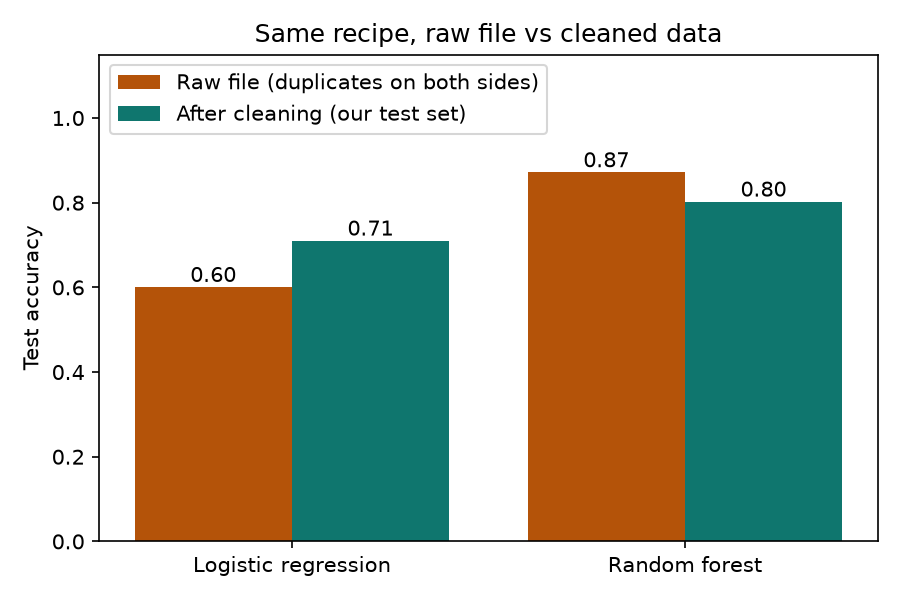

threshold_curve.png


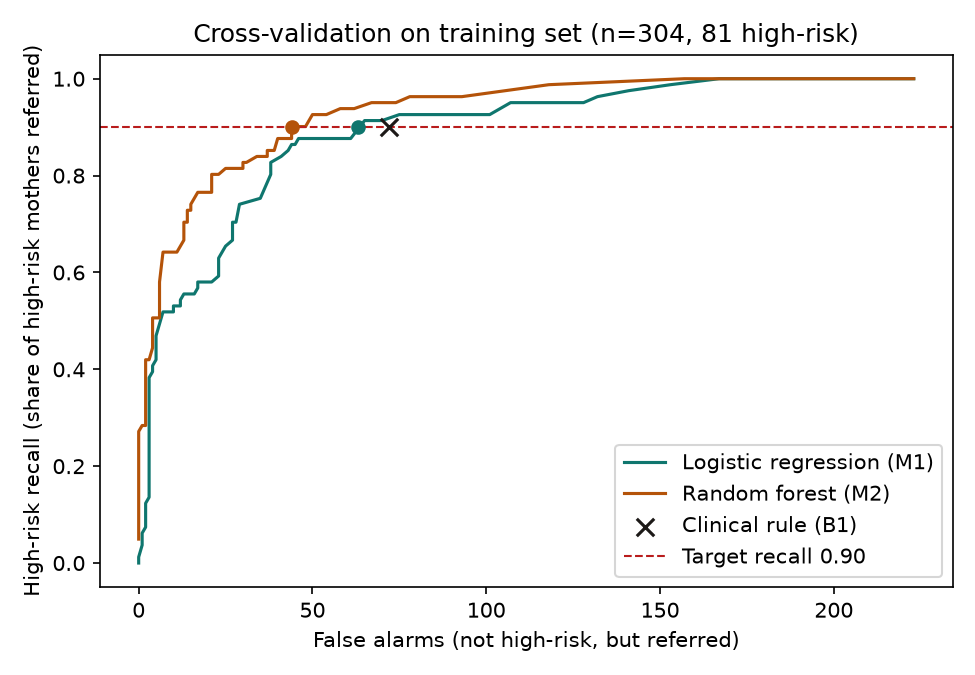

confusion_m1_triage.png


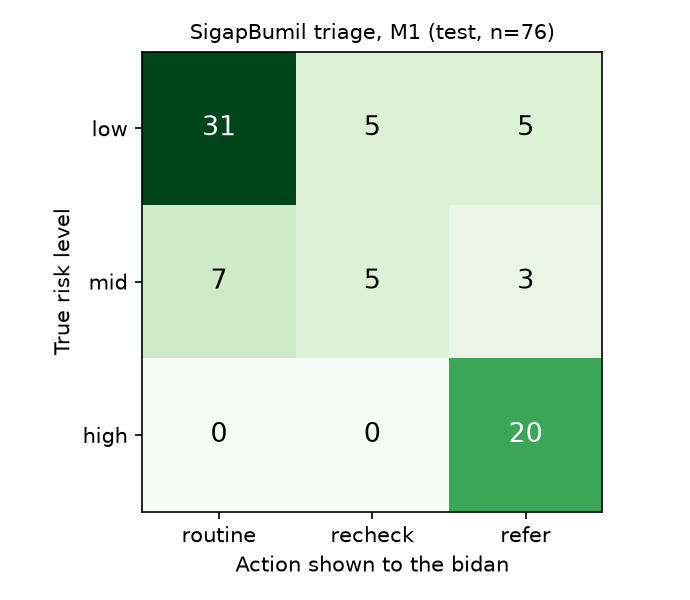

In [7]:
from IPython.display import Image, display

# leakage: accuracy with and without duplicate rows
# threshold curve: high-risk mothers caught vs false alarms at each referral threshold
# confusion matrix: the deployed model's action vs the true label, on the test set
for plot in ["leakage.png", "threshold_curve.png", "confusion_m1_triage.png"]:
    print(plot)
    display(Image(filename="results/" + plot, width=640))

## 7. Optional: rebuild everything

Uncomment to rerun the whole pipeline (cleaning, models, evaluation, export). `ucimlrepo` is the one library Colab does not have. Colab's library versions differ from the pinned ones, so tiny differences are possible; for an exact rebuild use `requirements.txt` locally.

In [8]:
# !pip install -q ucimlrepo
# !python pipeline/run_all.py
print("Skipped: the saved results in results/ are shown above.")

Skipped: the saved results in results/ are shown above.


---
Live site: https://sycthePlays.github.io/SigapBumil/ · Code and write-up: https://github.com/SycthePlays/SigapBumil

**This project is a prototype and is not medical advice.**